# 03 · The dbt models and the revenue they produce

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mohammedelsayed741996-blip/berlin-data-portfolio/blob/main/b2b-saas-data-platforms/saas-revenue-elt/notebooks/03_dbt_models_and_revenue.ipynb)

Transformations live in `dbt_project/` as a standard dbt project: sources, staging views, intermediate tables, marts, schema tests and singular tests. Locally they run on a small built-in runner over SQLite. CI also runs the same project with real dbt on DuckDB, with date logic kept in cross-database macros.

In [1]:
import os, sys, subprocess, warnings
from pathlib import Path

REPO = "https://github.com/mohammedelsayed741996-blip/berlin-data-portfolio.git"
PROJECT = "b2b-saas-data-platforms/saas-revenue-elt"

if "google.colab" in sys.modules:
    if not Path("/content/berlin-data-portfolio").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO, "/content/berlin-data-portfolio"], check=True)
    os.chdir(f"/content/berlin-data-portfolio/{PROJECT}")
else:
    here = Path.cwd()
    while not (here / "src" / "saas_elt").exists() and here != here.parent:
        here = here.parent
    os.chdir(here)

sys.path.insert(0, str(Path.cwd() / "src"))
warnings.filterwarnings("ignore")
import logging, shutil
logging.basicConfig(level=logging.ERROR)
import pandas as pd
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 90)
from IPython.display import Image, display
print("Project folder:", Path.cwd().name)

Project folder: saas-revenue-elt


In [2]:
from saas_elt import config
from saas_elt.pipeline import run_simulation
from saas_elt import reporting

workdir = Path("workdir/notebook_run")
if workdir.exists():
    shutil.rmtree(workdir)
sim = run_simulation(config.RunSettings(workdir=workdir), progress=True)
wh = sim.warehouse
q = lambda sql: pd.read_sql_query(sql, wh.conn)
print(f"{len(sim.runs)} daily runs, {sum(r.status == 'success' for r in sim.runs)} successful")

2026-07-01: success
2026-07-16: success
2026-07-31: success
2026-08-15: success
2026-08-30: success
2026-09-13: failed (transform, test, reconcile, housekeeping, publish)
2026-09-14: success
2026-09-29: success
93 daily runs, 92 successful


In [3]:
from saas_elt.minidbt import DbtProject
project = DbtProject(config.DBT_DIR, wh.conn, vars={"start_date": "2026-06-30", "run_date": "2026-09-30"})
pd.DataFrame([{"model": n.name, "kind": n.kind, "materialized": n.config.get("materialized", "seed"),
               "depends_on": ", ".join(sorted(n.refs) + [f"source:{s[1]}" for s in sorted(n.sources)])}
              for n in project.nodes.values()]).sort_values(["kind", "model"])

,model,kind,materialized,depends_on
3,dim_accounts,model,table,"fct_mrr_daily, stg_crm__accounts, stg_crm__subscriptions"
4,fct_invoices,model,incremental,stg_billing__invoices
5,fct_mrr_daily,model,table,"int_date_spine, int_subscription_versions"
6,fct_mrr_movements_monthly,model,table,"fct_mrr_daily, int_date_spine"
7,fct_product_usage_daily,model,incremental,stg_events__product_events
1,int_date_spine,model,table,
2,int_subscription_versions,model,table,source:crm_subscriptions
8,rpt_revenue_monthly,model,table,fct_mrr_movements_monthly
9,stg_billing__invoices,model,view,"fx_rates, source:billing_invoices"
10,stg_crm__accounts,model,view,source:crm_accounts


## Incremental models

`fct_product_usage_daily` re-aggregates the last three days on every run, because events can arrive up to two days late. The same file compiles to two different queries:

In [4]:
node = project.nodes["fct_product_usage_daily"]
for label, inc in [("first build", False), ("incremental build", True)]:
    sql = project.render(node, incremental=inc)
    print(f"--- {label}: everything after FROM ---")
    print(sql.split("from stg_events__product_events")[1].strip(), "\n")

--- first build: everything after FROM ---
group by account_id, event_date 

--- incremental build: everything after FROM ---
-- coalesce: an empty target (first run had no events yet) must not filter everything out
where event_date >= coalesce(
    (select date(max(event_date), '-3 day') from fct_product_usage_daily),
    '1900-01-01')

group by account_id, event_date 



## SCD type 2 from an append-only raw layer

Every subscription change lands as a new raw row. `int_subscription_versions` turns them into validity ranges, and `fct_mrr_daily` reads the version that was valid at the end of each day.

In [5]:
q("SELECT subscription_id, plan, seats, mrr_eur, valid_from_date, valid_to_date FROM int_subscription_versions WHERE subscription_id IN (SELECT subscription_id FROM int_subscription_versions GROUP BY 1 HAVING COUNT(*) >= 3 LIMIT 2) ORDER BY 1, valid_from_date")

,subscription_id,plan,seats,mrr_eur,valid_from_date,valid_to_date
0,SUB-00004,Growth,4,236.0,2026-06-30,2026-08-15
1,SUB-00004,Growth,5,295.0,2026-08-15,2026-09-06
2,SUB-00004,Growth,5,0.0,2026-09-06,NaN
3,SUB-00010,Starter,15,435.0,2026-06-30,2026-08-17
4,SUB-00010,Starter,18,522.0,2026-08-17,2026-08-23
5,SUB-00010,Growth,18,1062.0,2026-08-23,NaN


## Revenue bridge

The quarter closes at about EUR 250k MRR, or EUR 3.0M ARR. Net revenue retention is above 100% in July and August and dips to 99.5% in September, when churn picks up.

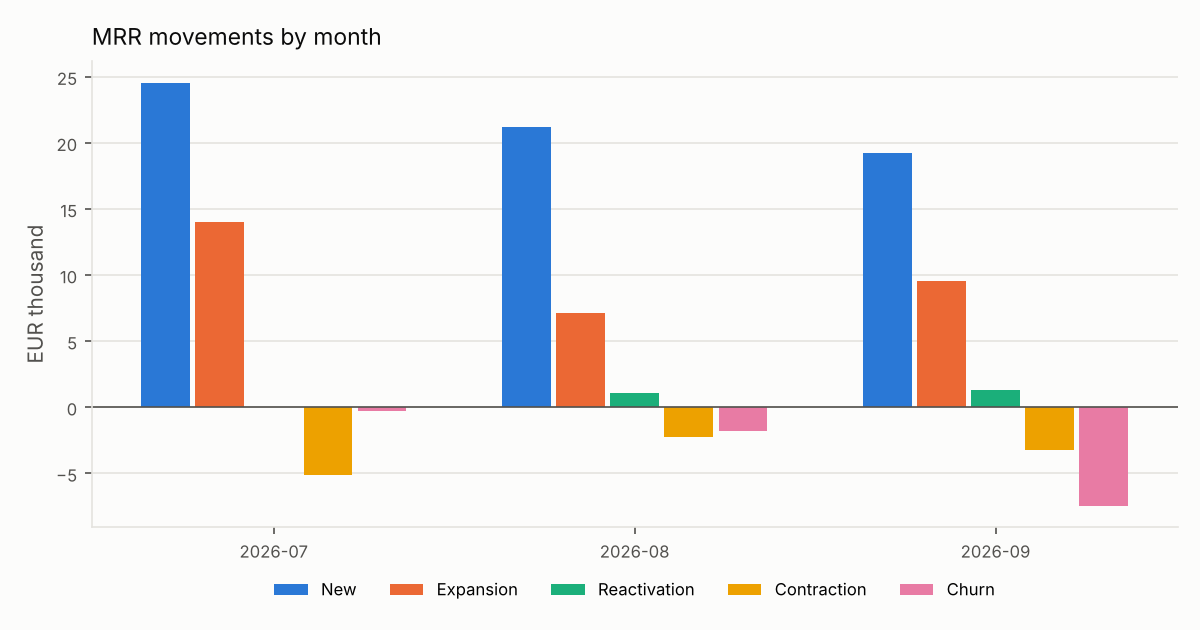

,period_month,opening_mrr,new_mrr,expansion_mrr,contraction_mrr,churned_mrr,reactivation_mrr,closing_mrr,closing_arr,new_logos,churned_logos,net_revenue_retention,gross_revenue_retention
0,2026-07-01,171575.0,24566.0,14011.0,-5119.0,-290.0,0.0,204743.0,2456916.0,33,3,1.0501,0.9685
1,2026-08-01,204743.0,21240.0,7138.0,-2225.0,-1777.0,1073.0,230192.0,2762304.0,36,7,1.0153,0.9805
2,2026-09-01,230192.0,19228.0,9534.0,-3249.0,-7438.0,1313.0,249580.0,2994960.0,30,10,0.9950,0.9536


In [6]:
display(Image(filename=str(reporting.plot_revenue_bridge(sim, Path("outputs/figures/revenue_bridge.png")))))
q("SELECT * FROM rpt_revenue_monthly")

In [7]:
q("SELECT segment, COUNT(*) AS customers, ROUND(SUM(current_mrr_eur)) AS mrr_eur FROM dim_accounts WHERE customer_status = 'active' GROUP BY 1 ORDER BY 3 DESC")

,segment,customers,mrr_eur
0,Enterprise,51,104295.0
1,MidMarket,126,89387.0
2,SMB,228,55898.0
